In [1]:
import torch
import importlib
import numpy as np

import xarray as xr
import os
from data_functions import dataset
from collate import pad_nextoso_collate
import utils_data


PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_TO_OSO_CLASSES = (
    "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"
)

batch_size = 4

In [2]:
dt = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    norm=True,
    folds=None,
    date_type="raw",
)
dl = torch.utils.data.DataLoader(
    dt, batch_size=batch_size, collate_fn=pad_nextoso_collate, shuffle=True
)

(<Figure size 1500x800 with 10 Axes>, <Figure size 800x800 with 2 Axes>)

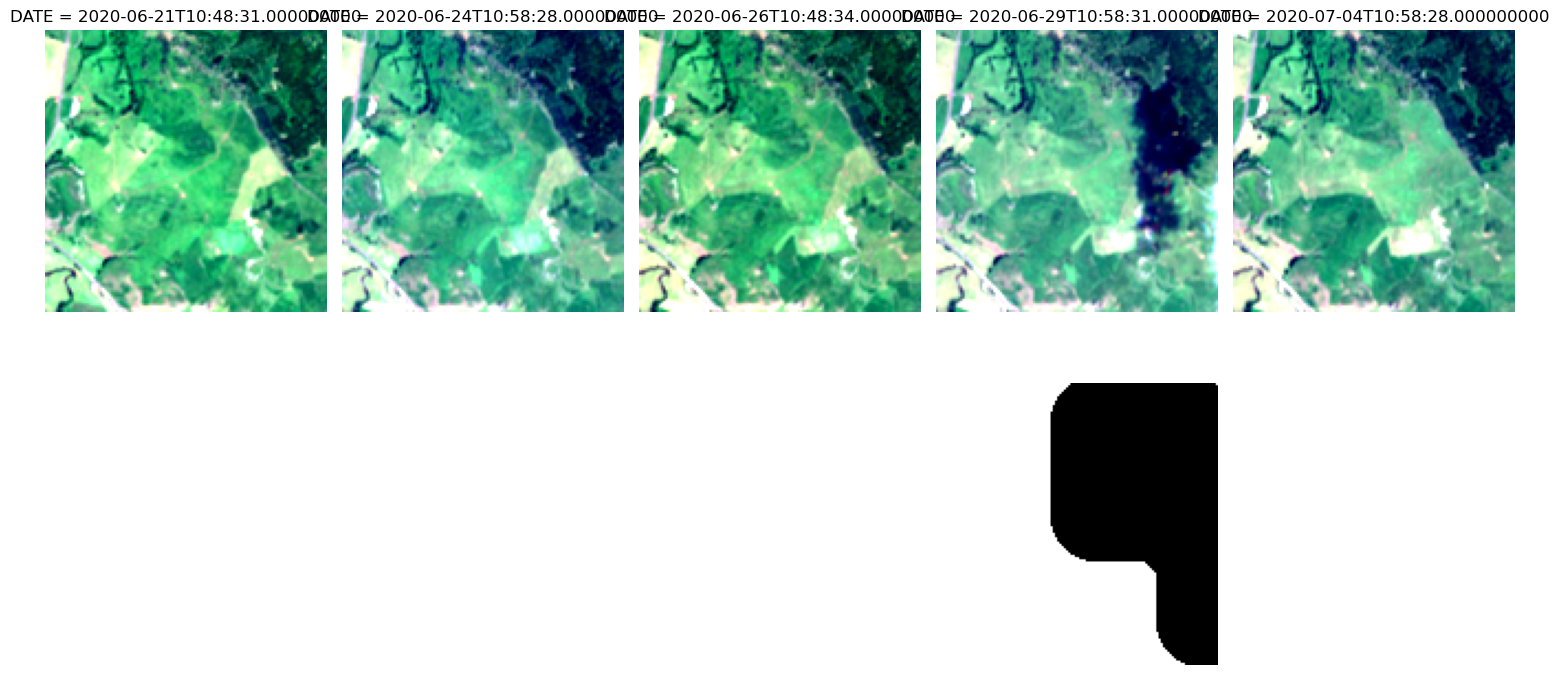

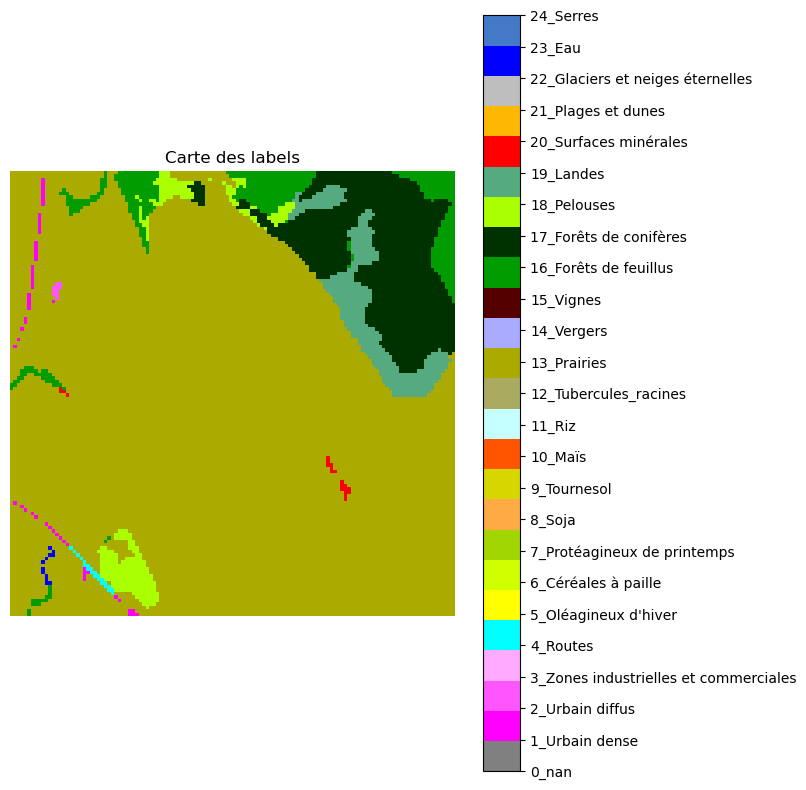

In [3]:
utils_data.plot_nextoso(dt, idx=100, first_date=20)

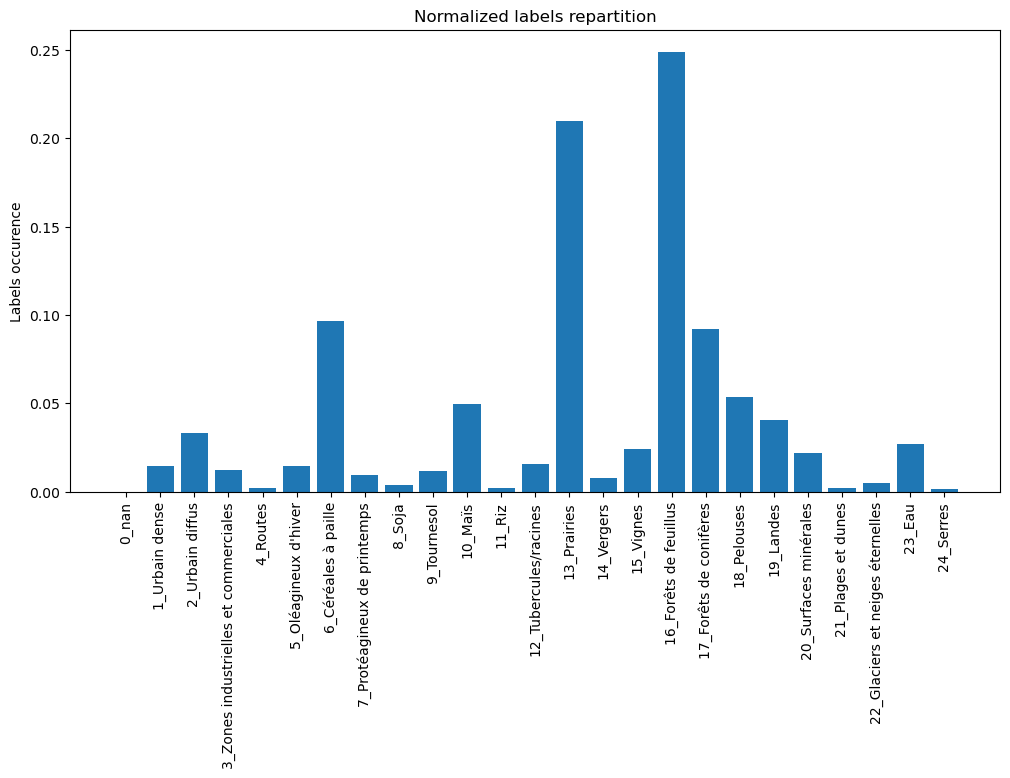

In [5]:
count = utils_data.count_label(dt)

In [6]:
np.max(count[1:]) / np.min(count[1:])

np.float64(138.47075713781493)

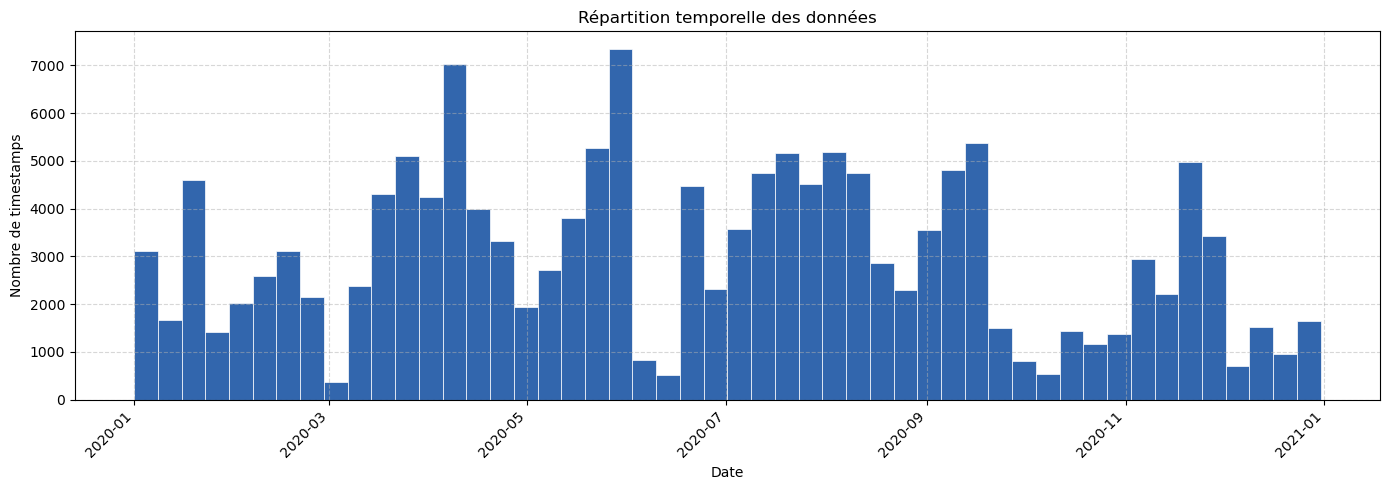

In [84]:
importlib.reload(utils_data)
dates = utils_data.count_timestep_dataloard(dt)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x77fb0eb12200>
Traceback (most recent call last):
  File "/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x77fb0eb12200>
Traceback (most recent call last):
  File "/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/to

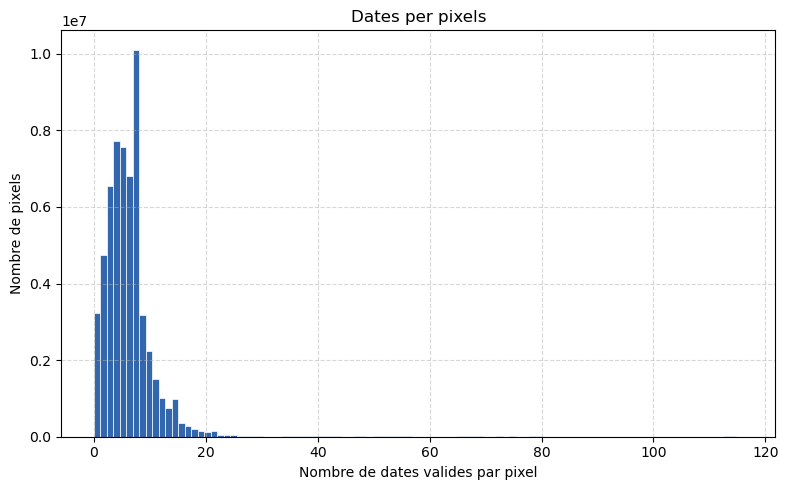

In [77]:
importlib.reload(utils_data)
dates = utils_data.histogram_valid_per_pixel(dt, density=False)

In [83]:
np.where(dates == 10)[0].shape

(2225589,)

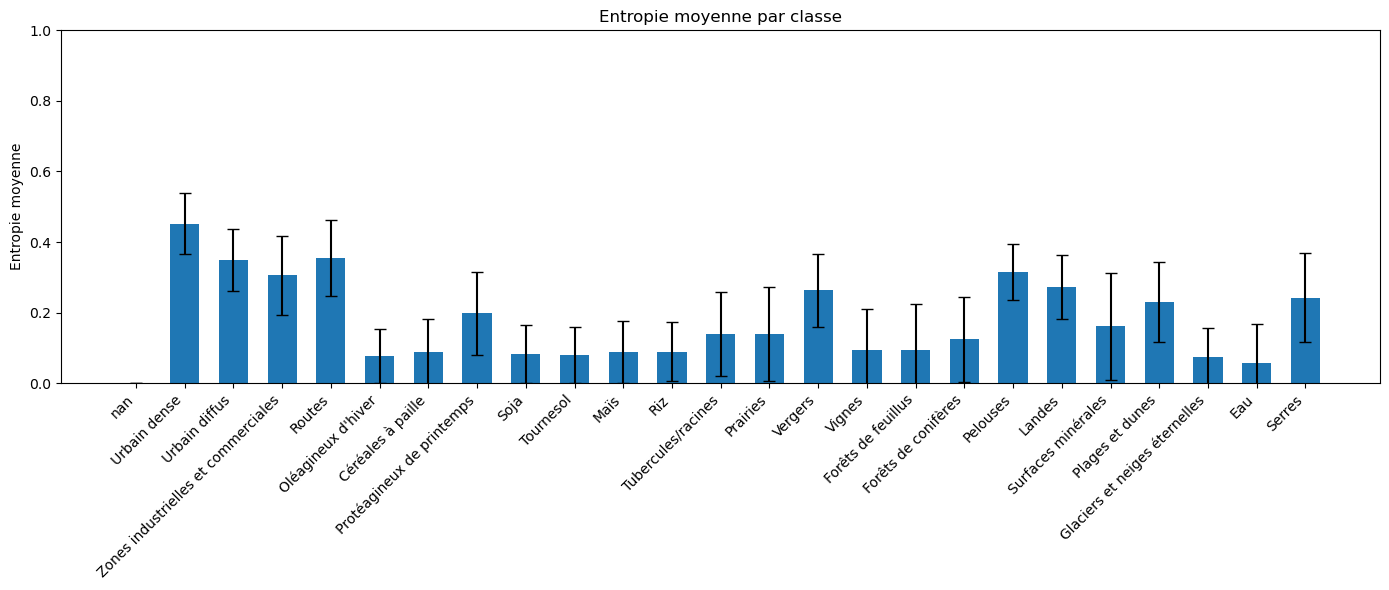

In [ ]:
entropy_per_class = utils_data.mean_entropy_per_class(
    PATH_TO_DATA_label, PATH_TO_OSO_CLASSES
)

In [ ]:
mean_entropy = utils_data.mean_entropy_per_class_per_eco_zone(
    PATH_TO_DATA_label, PATH_TO_OSO_CLASSES
)

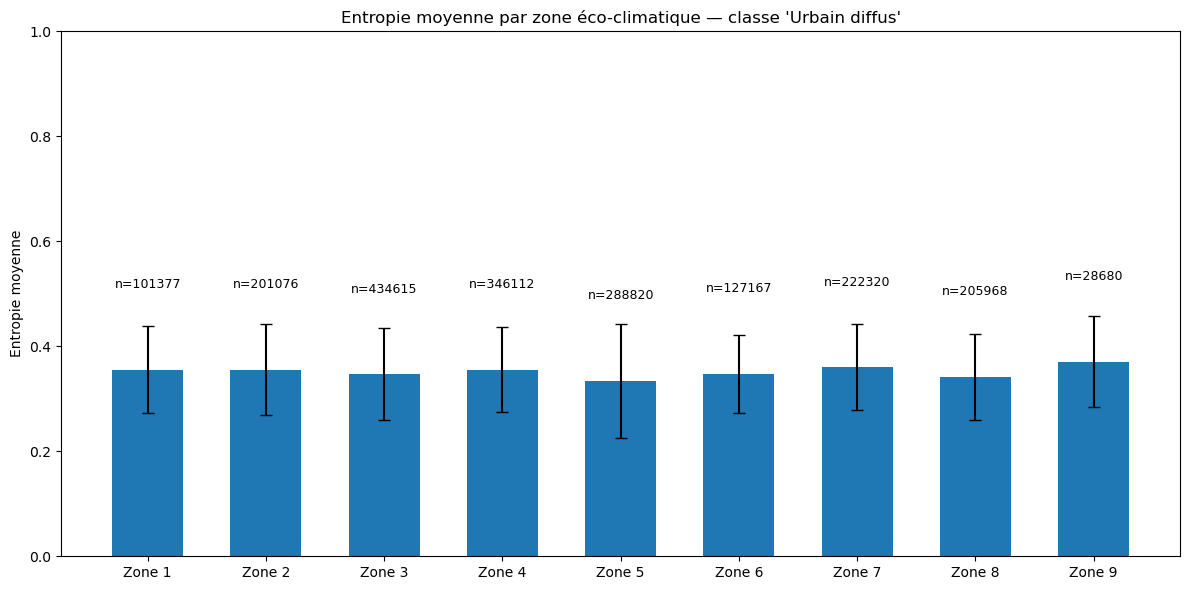

In [116]:
utils_data.plot_entropy_per_zone_for_class(mean_entropy=mean_entropy, classe=2)

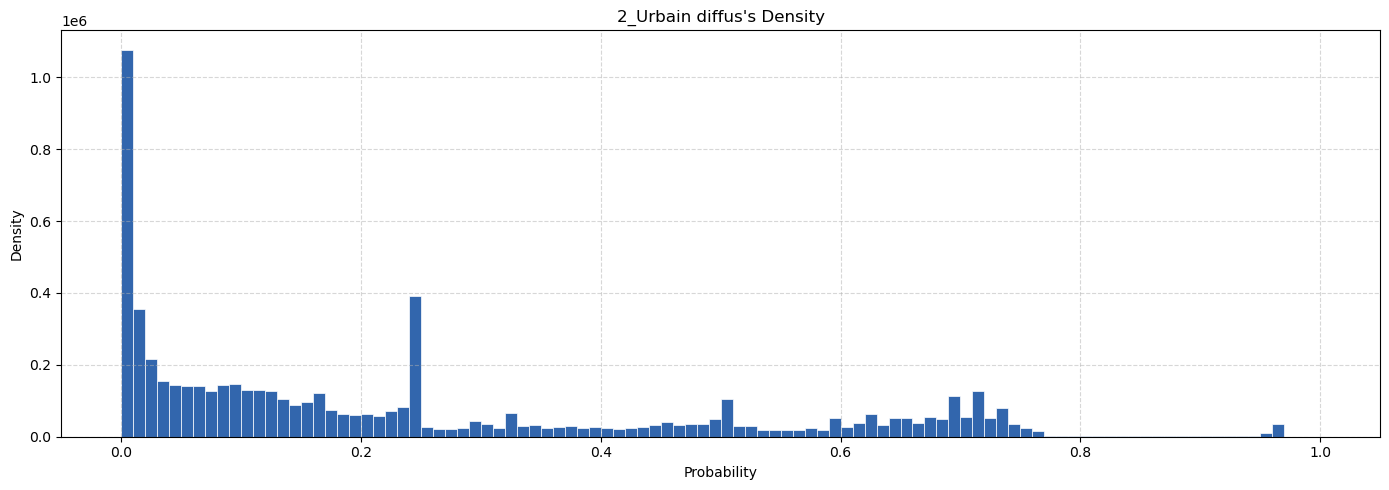

In [23]:
importlib.reload(utils_data)
density_class = utils_data.density_repartition(PATH_TO_DATA_label, "2_Urbain diffus")

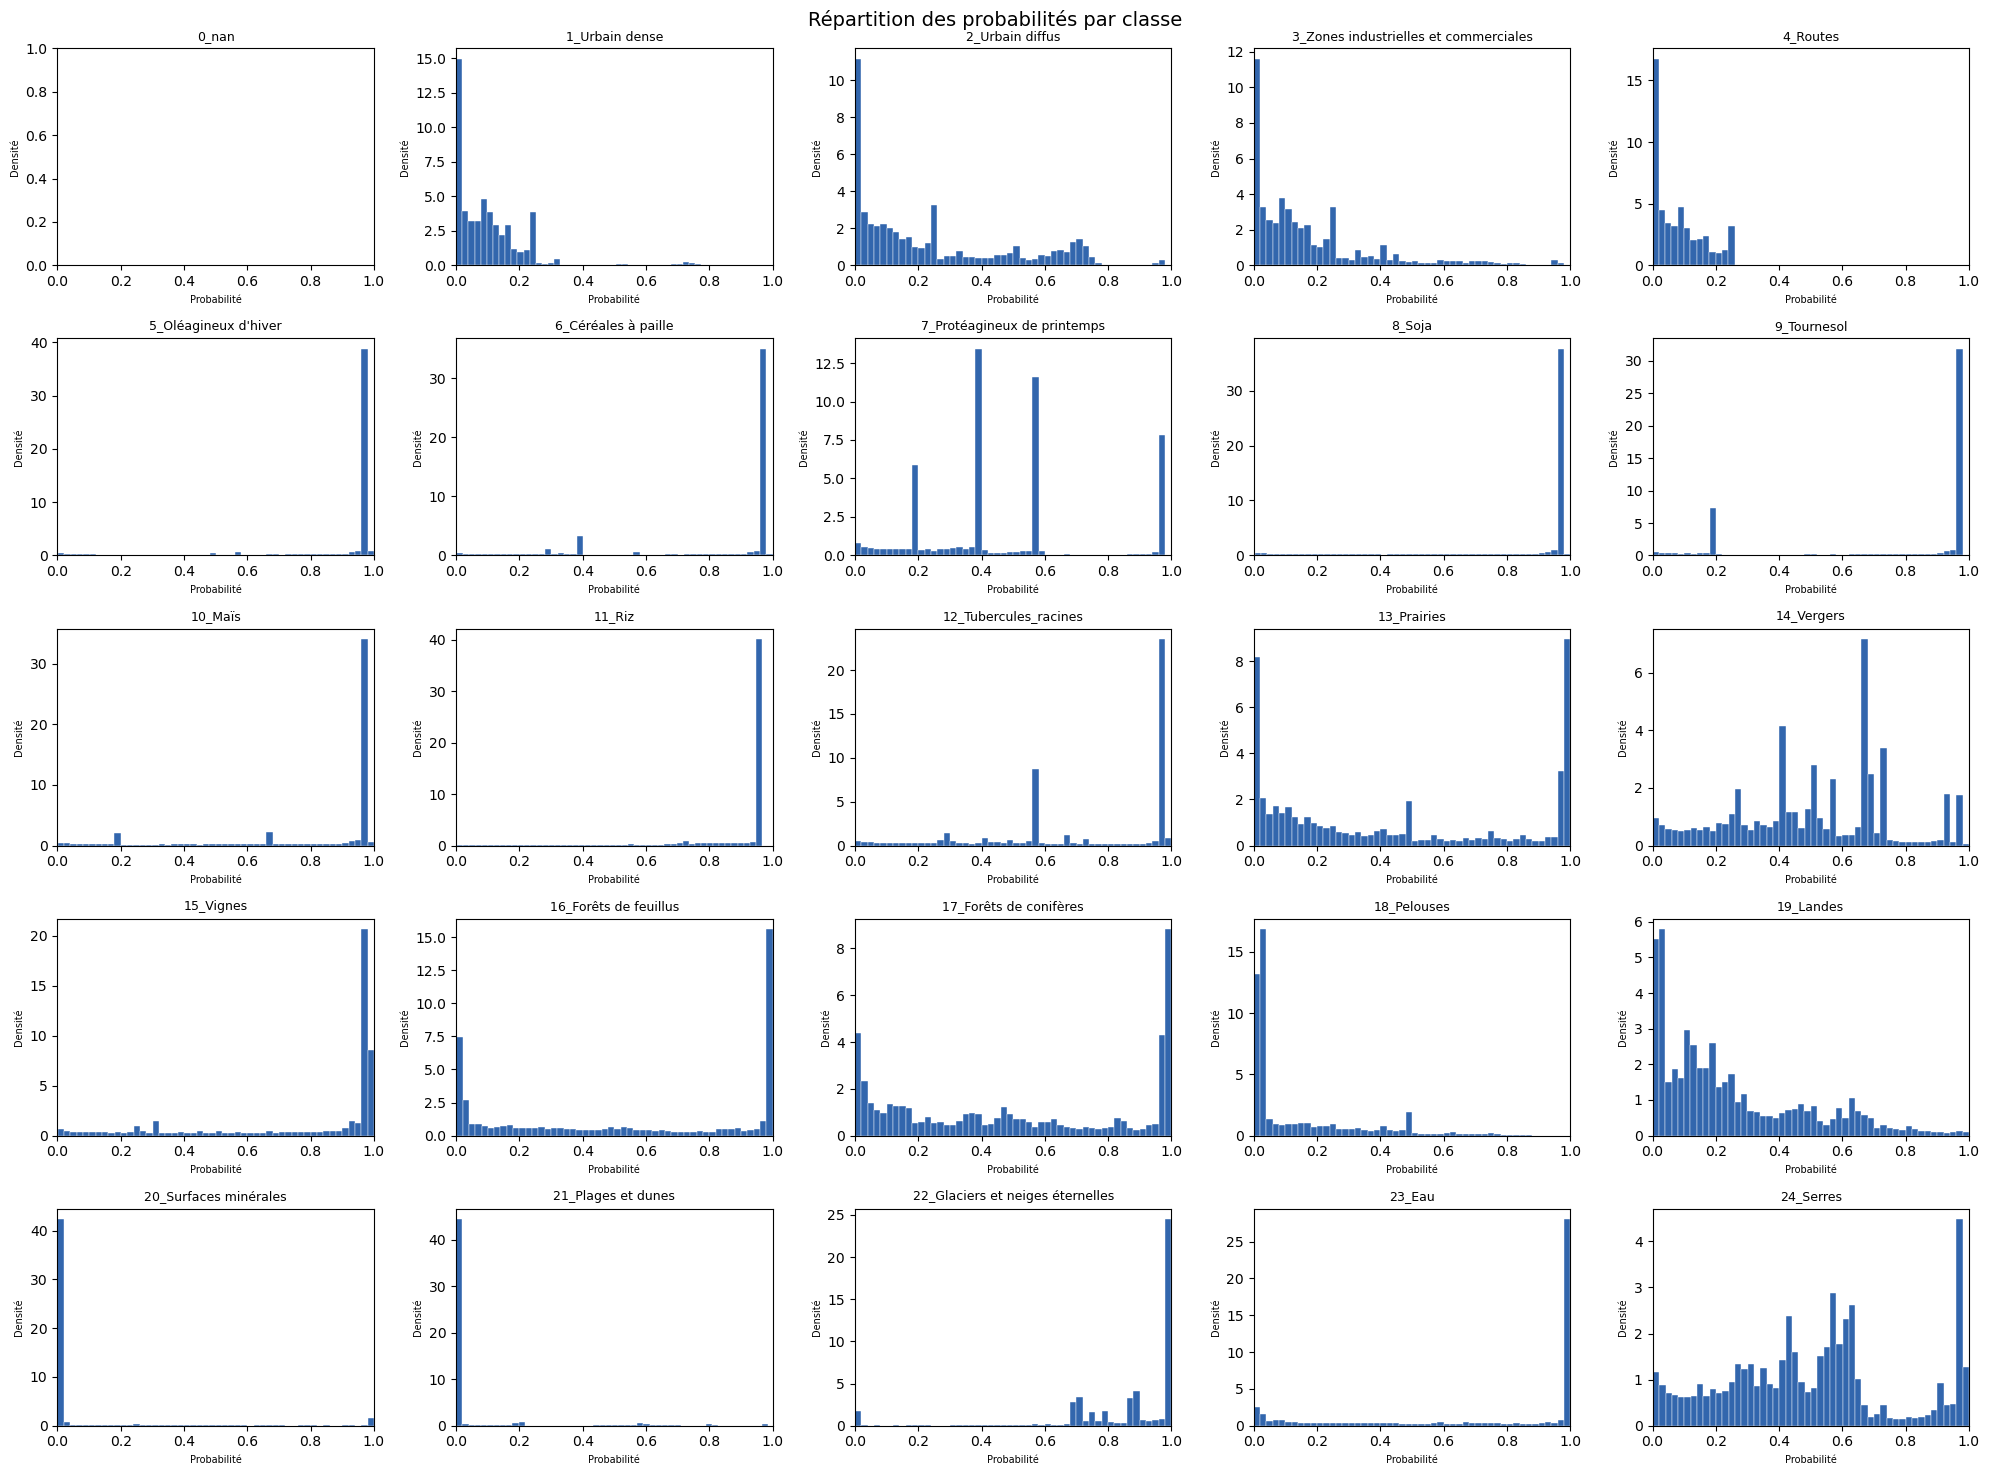

In [11]:
importlib.reload(utils_data)
density_all_class = utils_data.density_repartition_all_classes(
    PATH_TO_DATA_label, plot=True
)

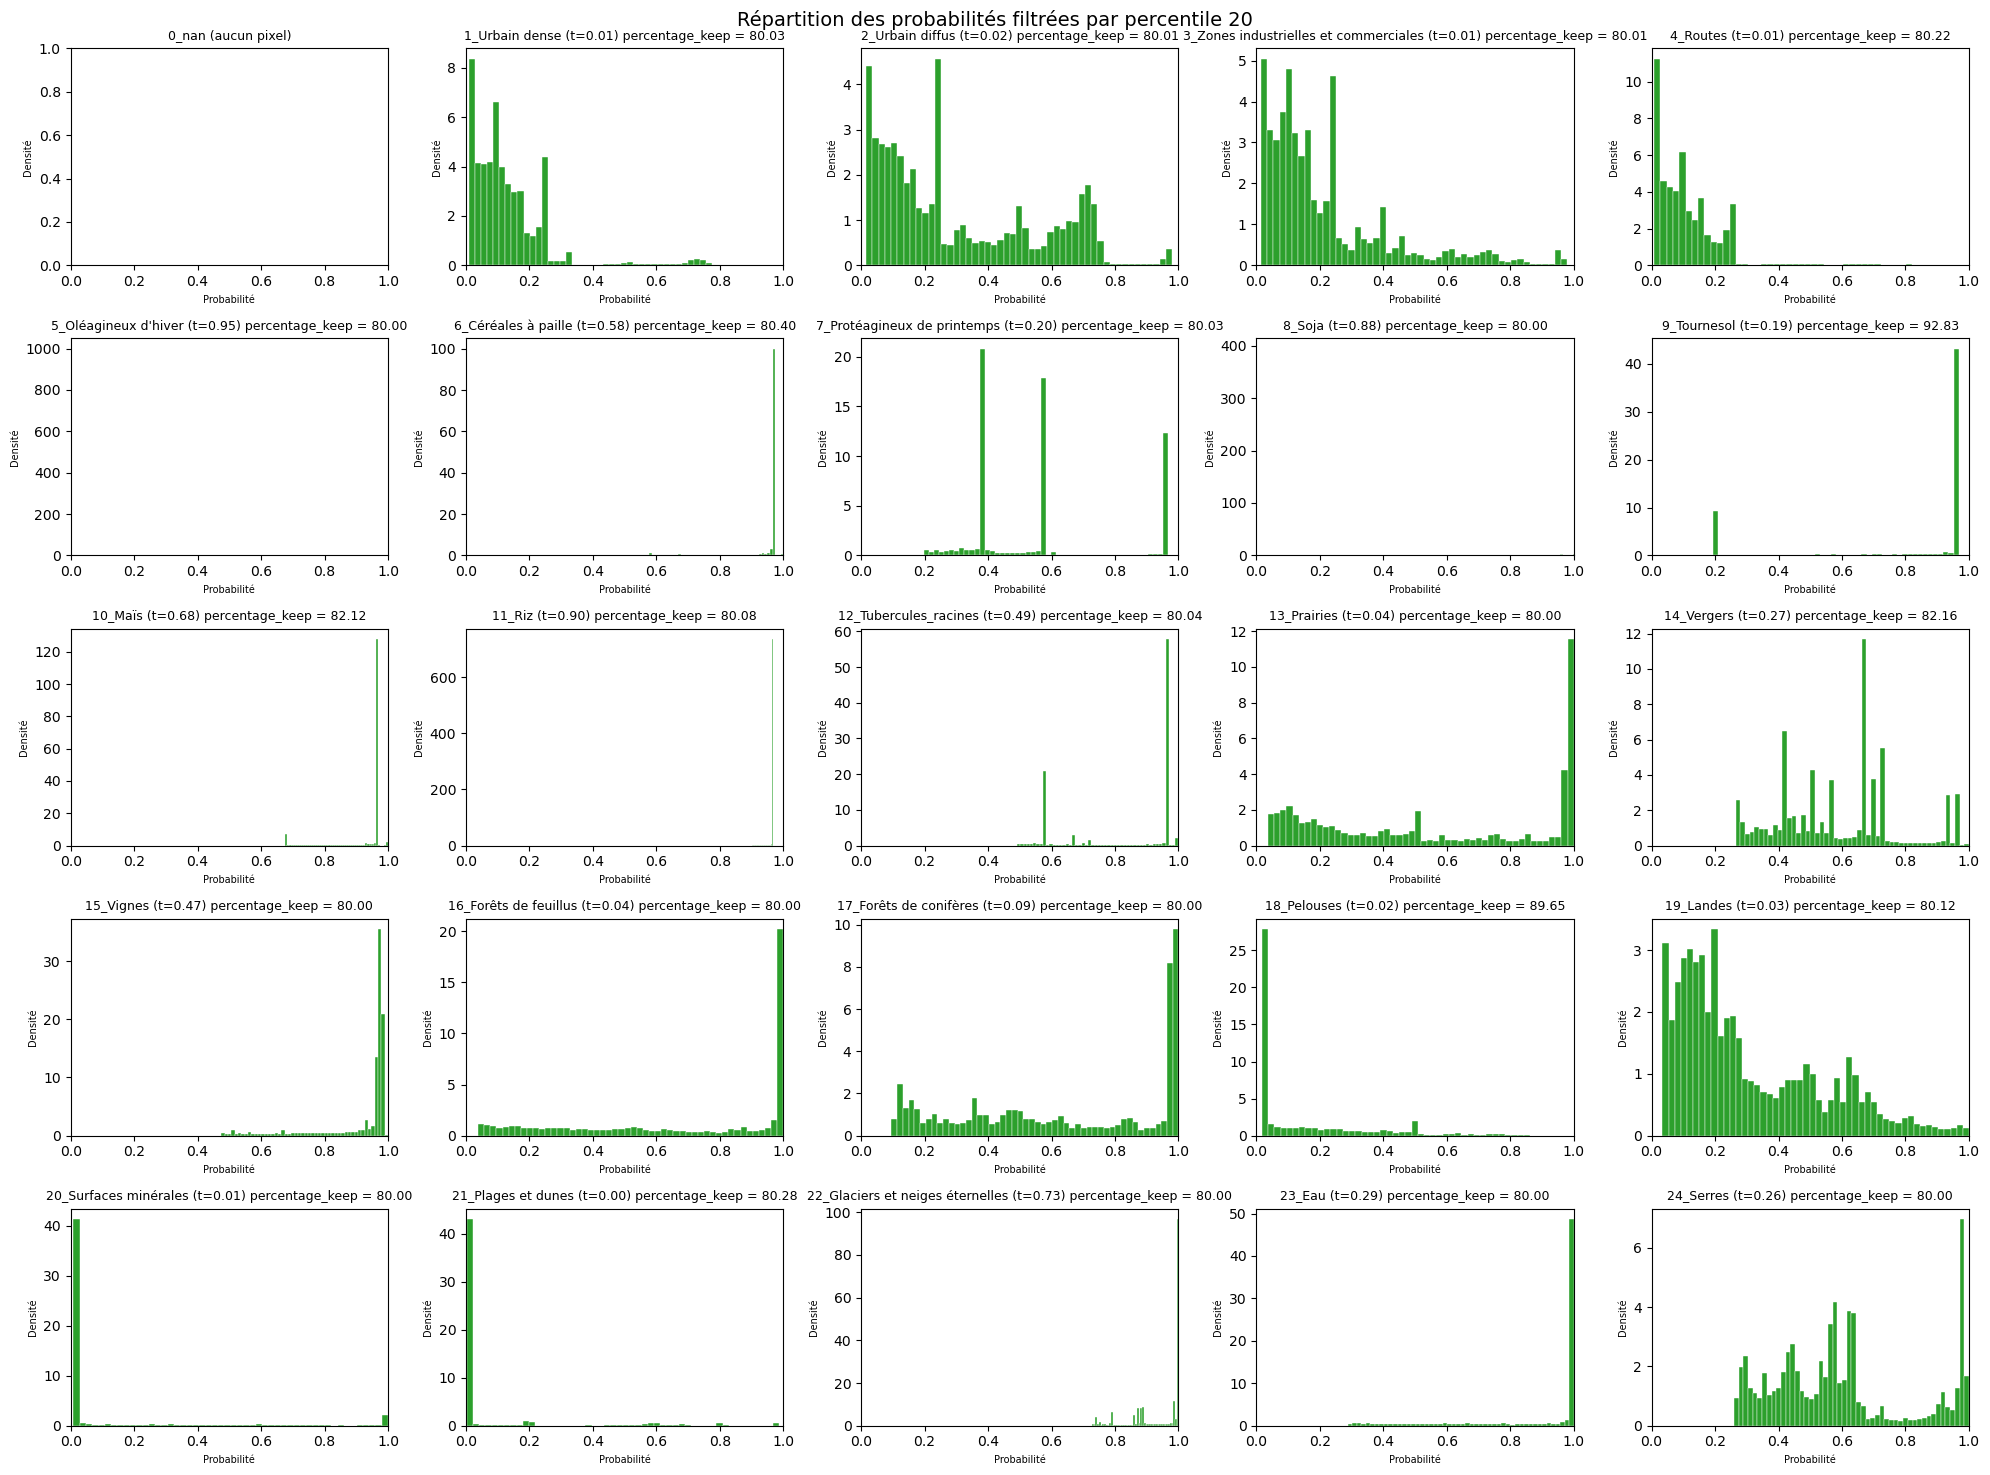

In [16]:
importlib.reload(utils_data)
thresholds, filtered_probas = utils_data.plot_filtered_probas(density_all_class, 20)

In [17]:
np.load("/home/hkerino/Documents/next_oso/data_functions/thresholds.npy")

array([0.        , 0.00845411, 0.01533505, 0.01391753, 0.00738397,
       0.95224839, 0.57636887, 0.19656019, 0.88248777, 0.19323671,
       0.67632848, 0.90211999, 0.49140048, 0.03660714, 0.26525199,
       0.47477531, 0.03810924, 0.09487965, 0.01690821, 0.03381642,
       0.0080981 , 0.00209895, 0.72727323, 0.28805238, 0.25914398])

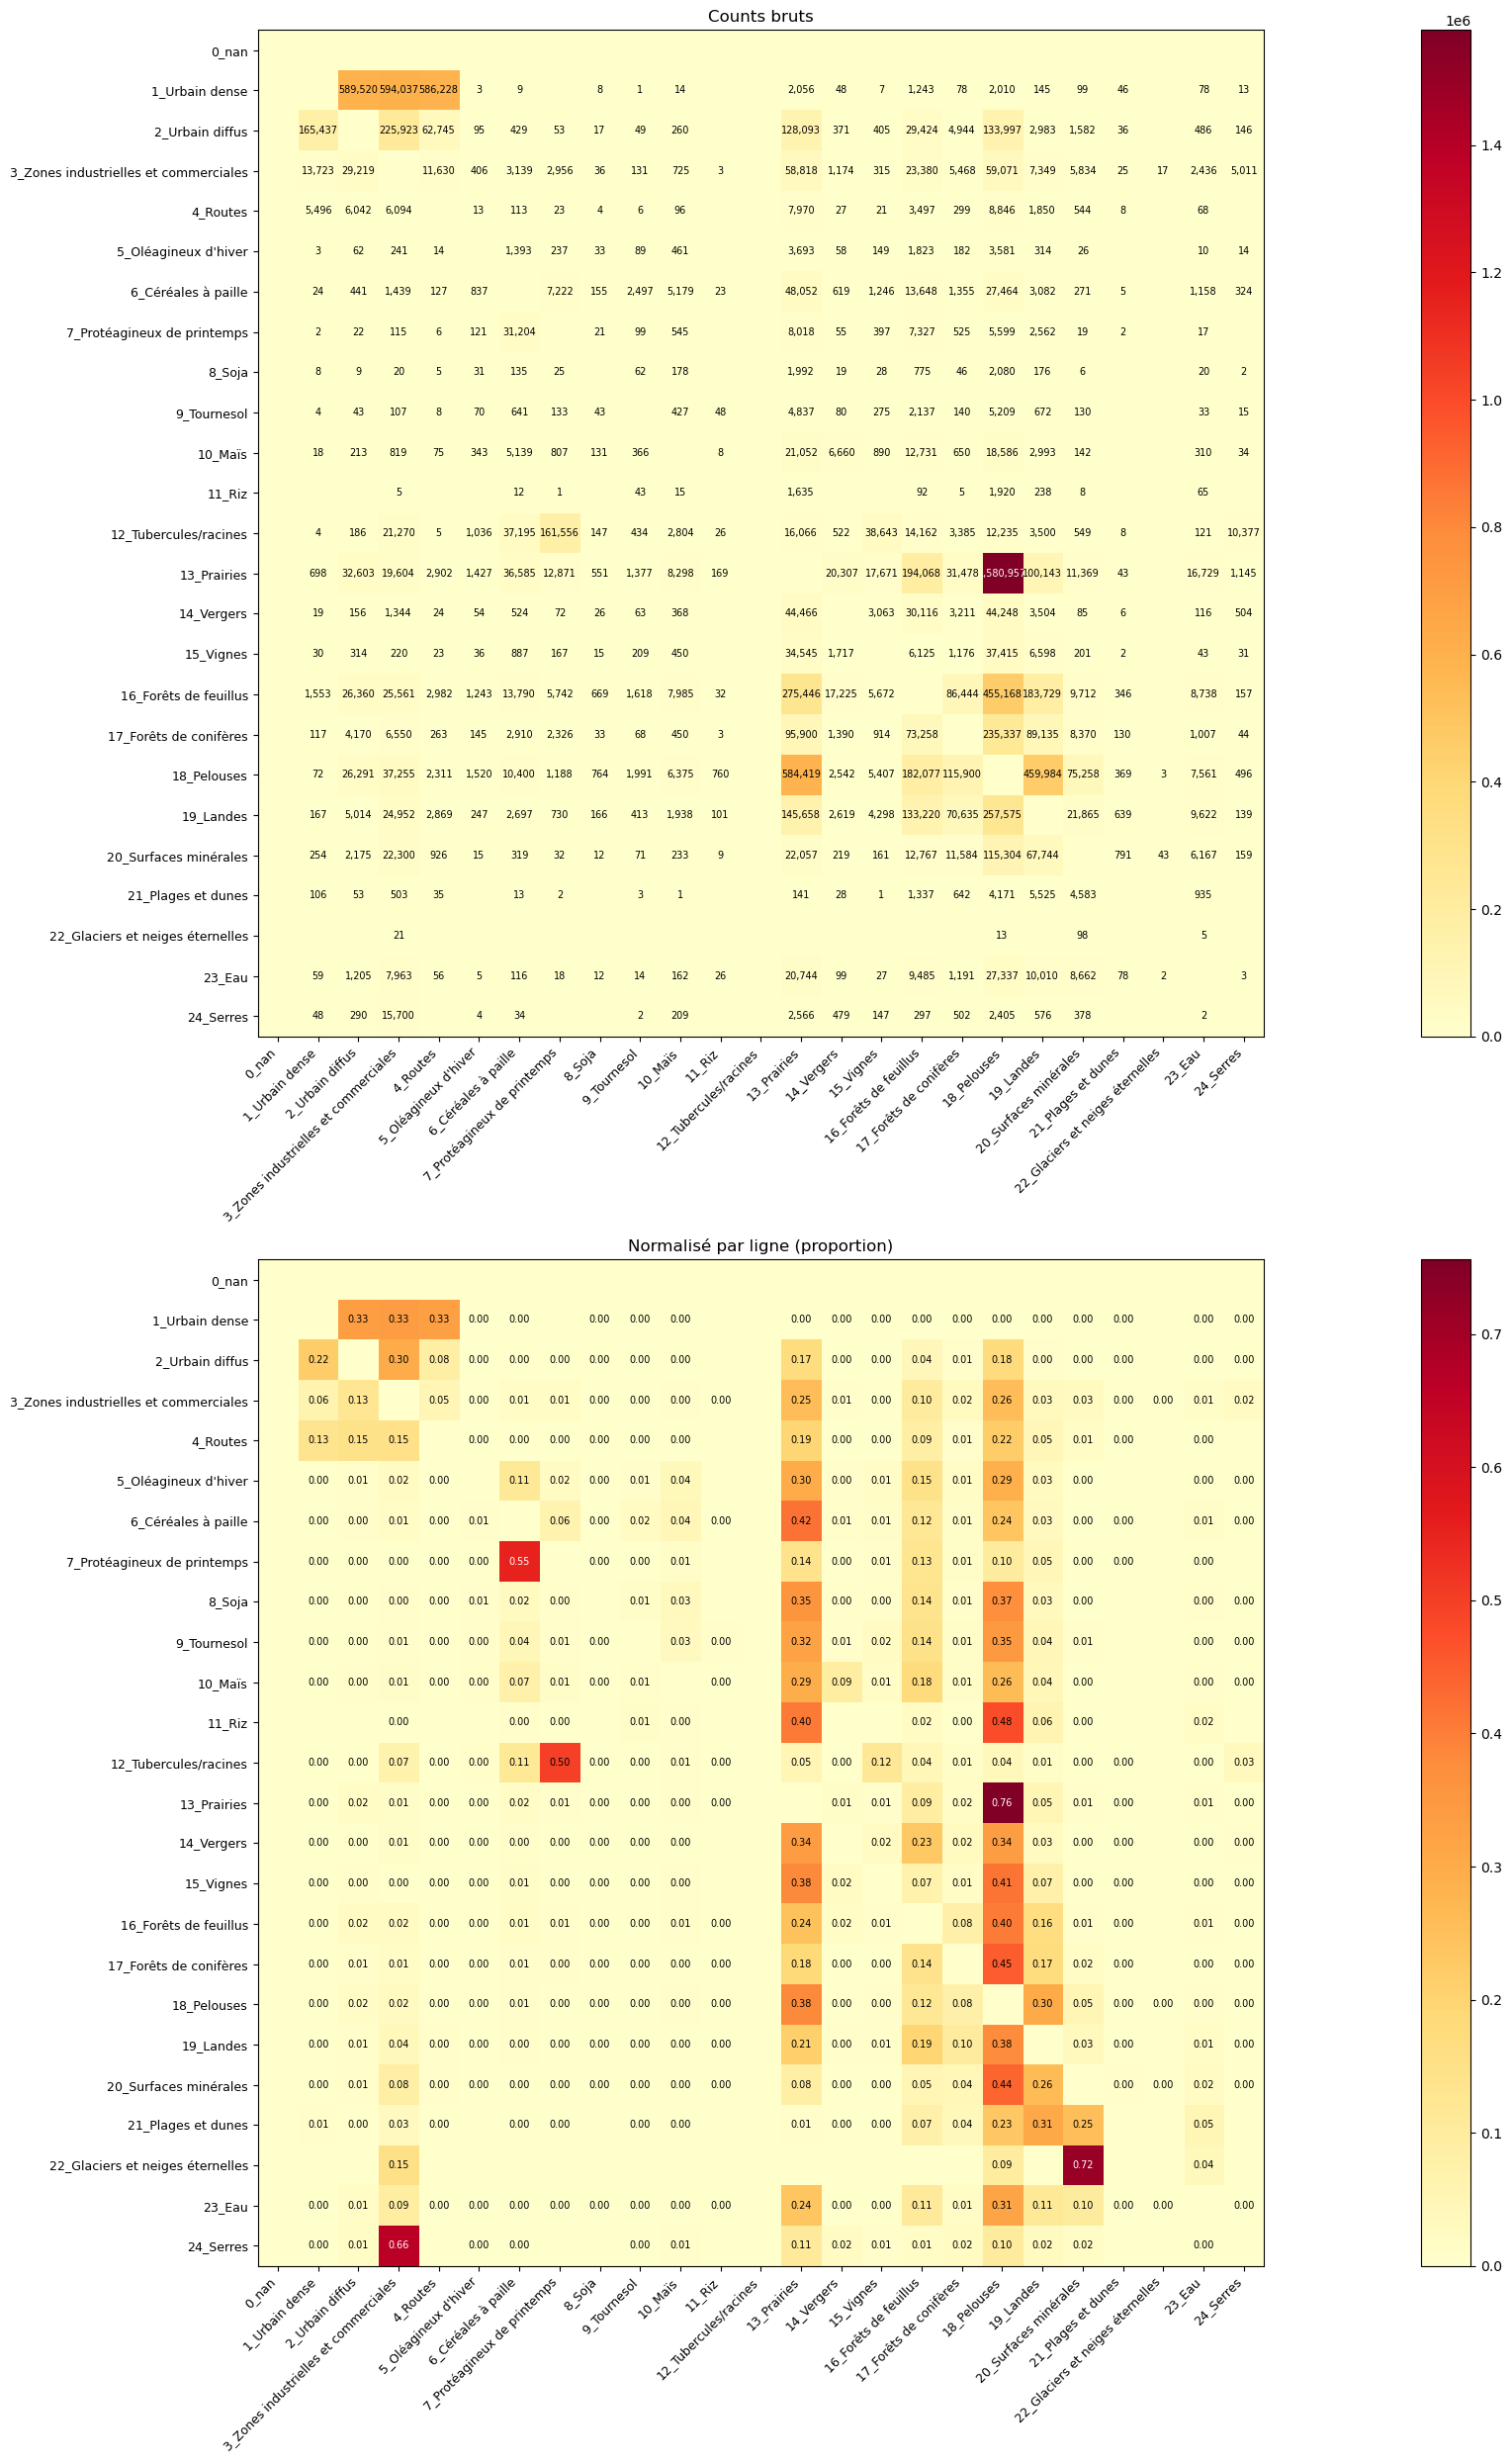

array([[      0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0],
       [      0,       0,  589520,  594037,  586228,       3,       9,
              0,       8,       1,      14,       0,       0,    2056,
             48,       7,    1243,      78,    2010,     145,      99,
             46,       0,      78,      13],
       [      0,  165437,       0,  225923,   62745,      95,     429,
             53,      17,      49,     260,       0,       0,  128093,
            371,     405,   29424,    4944,  133997,    2983,    1582,
             36,       0,     486,     146],
       [      0,   13723,   29219,       0,   11630,     406,    3139,
           2956,      36,     131,     725,       3,       0,   58818,
           1174,     315,   23380,    5468,   59071,    7349,    5834,
             

In [117]:
importlib.reload(utils_data)
utils_data.plot_label_confusion(
    PATH_TO_DATA_label,
    PATH_TO_OSO_CLASSES,
    proba_threshold=0.5,
    secondary_threshold=0.2,
)

In [26]:
nan_ids = utils_data.find_nan_label(
    dataset.next_oso_Dataset(
        path_s2=PATH_TO_DATA_s2,
        path_label=PATH_TO_DATA_label,
        path_oso_class=PATH_TO_OSO_CLASSES,
        return_id=True,
    )
)

In [60]:
nan_ids

['3205',
 '3515',
 '0938',
 '1408',
 '1805',
 '2317',
 '0611',
 '1755',
 '1916',
 '2771',
 '2185',
 '3314',
 '3416',
 '2002',
 '2660',
 '3039',
 '1570',
 '2632',
 '2305',
 '3316',
 '2148',
 '2686',
 '3311',
 '1797',
 '2152',
 '2447',
 '3090',
 '2071',
 '0897',
 '2868']

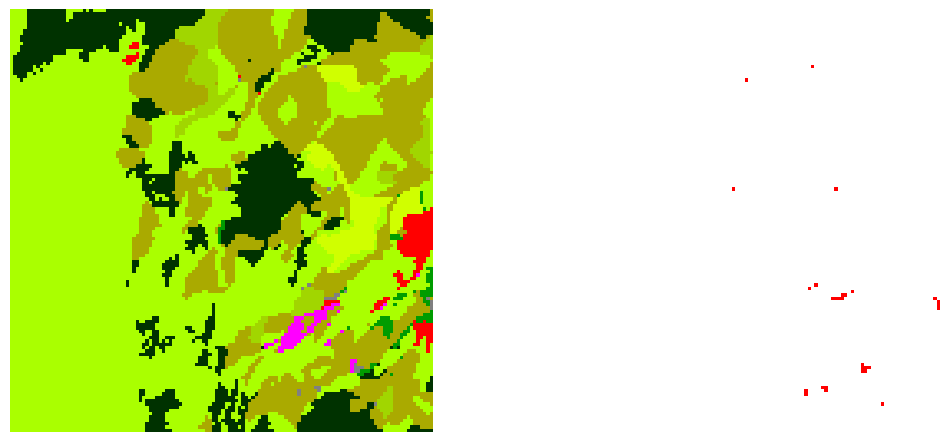

In [ ]:
utils_data.plot_nan(
    xr.open_dataset(os.path.join(PATH_TO_DATA_label, f"label_{nan_ids[0]}.nc"))
)

In [58]:
importlib.reload(dataset)
d = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    norm=False,
    return_id=True,
    label_type="max_class",
)
id_s2 = "0257"

(x, date, mask), y, id = d[id_s2]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6167.0].


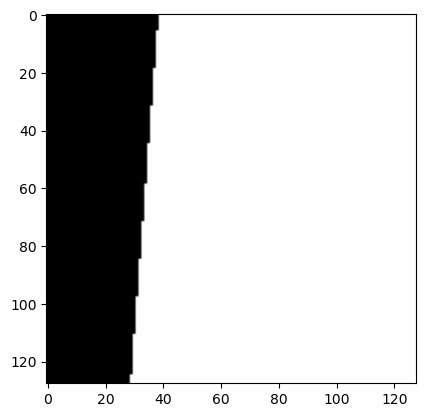

In [55]:
from matplotlib import pyplot as plt

plt.imshow(utils_data.to_RGB(x[:, 0, :, :], norm=False))

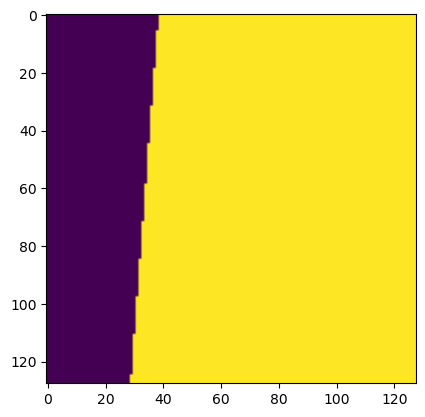

In [57]:
plt.imshow(mask[0, :, :])

In [ ]:
import pandas

names_class = (
    pandas.read_csv(
        "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"
    )
    .get("name_class")
    .values
)  # Doit contenir 25 entrées (0 à 24)

In [29]:
names_class

array(['0_nan', '1_Urbain dense', '2_Urbain diffus',
       '3_Zones industrielles et commerciales', '4_Routes',
       "5_Oléagineux d'hiver", '6_Céréales à paille',
       '7_Protéagineux de printemps', '8_Soja', '9_Tournesol', '10_Maïs',
       '11_Riz', '12_Tubercules_racines', '13_Prairies', '14_Vergers',
       '15_Vignes', '16_Forêts de feuillus', '17_Forêts de conifères',
       '18_Pelouses', '19_Landes', '20_Surfaces minérales',
       '21_Plages et dunes', '22_Glaciers et neiges éternelles', '23_Eau',
       '24_Serres'], dtype=object)

In [40]:
xr.open_dataset(os.path.join(PATH_TO_DATA_label, f"label_{nan_ids[10]}.nc"))[
    names_class[23]
]

<xarray.DataArray '23_Eau' (y: 128, x: 128)> Size: 66kB
[16384 values with dtype=float32]
Coordinates:
  * y        (y) float32 512B 7.086e+06 7.086e+06 ... 7.085e+06 7.085e+06
  * x        (x) float32 512B 6.487e+05 6.487e+05 ... 6.499e+05 6.499e+05
Attributes:
    grid_mapping:  crs